# Fraud Detection on Bank Transactions: EDA & Unsupervised Anomaly Detection

**Goal:** Explore the *Bank Transaction Dataset for Fraud Detection* and test unsupervised anomaly detection methods on it.

**Key constraint:** The dataset contains **no fraud label**, so classic supervised classification is not possible. Anomaly detection ranks transactions by how unusual they are. It does not tell us what is actually fraud.

**Outline**
1. Setup & imports
2. Load data
3. First exploration
4. Datetime conversion
5. Account ID analysis
6. Feature engineering exploration (which ideas work, which do not)
7. Prepare features for the model
8. Isolation Forest
9. Local Outlier Factor (LOF)

Reusable code lives in `src/`. This notebook is for exploration and for documenting decisions.

## 1. Setup & Imports

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import MinMaxScaler, RobustScaler

# Make the project root importable, so that `src/` can be used from inside notebooks/
sys.path.append("..")
from src.config import RANDOM_STATE
from src.feature_engineering import FEATURES_FOR_MODEL, prepare_features

## 2. Load Data

In [2]:
data = pd.read_csv("../data/bank_transactions_data_2.csv")

## 3. First Exploration

In [3]:
data.info()
display(data.describe())
display(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   str    
 1   AccountID                2512 non-null   str    
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   str    
 4   TransactionType          2512 non-null   str    
 5   Location                 2512 non-null   str    
 6   DeviceID                 2512 non-null   str    
 7   IP Address               2512 non-null   str    
 8   MerchantID               2512 non-null   str    
 9   Channel                  2512 non-null   str    
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   str    
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance           2512 non-n

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2512.000000,2512.000000,2512.000000,2512.000000,2512.000000
mean,297.593778,44.673965,119.643312,1.124602,5114.302966
std,291.946243,17.792198,69.963757,0.602662,3900.942499
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.885000,27.000000,63.000000,1.000000,1504.370000
50%,211.140000,45.000000,112.500000,1.000000,4735.510000
75%,414.527500,59.000000,161.000000,1.000000,7678.820000
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
dtype: int64

**Observations**
- 2,512 rows, 16 columns, no missing values. A dataset this clean suggests that it is synthetic.
- All date columns are stored as strings and must be converted before we can calculate time differences.

## 4. Convert Datetime Format

Dates are parsed into `datetime` so that we can calculate time differences. Subtracting strings would fail, and sorting them only works by accident for this date format.

In [4]:
data["TransactionDate_dt"] = pd.to_datetime(data["TransactionDate"])
data["PreviousTransactionDate_dt"] = pd.to_datetime(data["PreviousTransactionDate"])

# Evidence for the finding below: range of both date columns
data[["TransactionDate_dt", "PreviousTransactionDate_dt"]].agg(["min", "max"])

,TransactionDate_dt,PreviousTransactionDate_dt
min,2023-01-02 16:00:06,2024-11-04 08:06:23
max,2024-01-01 18:21:50,2024-11-04 08:12:23


**Finding:** `PreviousTransactionDate` is not the previous transaction of an account. All values fall into a window of about six minutes on a single day in November 2024, which is after the last transaction in the data. It looks like an export timestamp, not customer behaviour. We therefore derive our own per-account version in Section 6.1.

## 5. Account ID Analysis

In [5]:
n_accounts = data["AccountID"].nunique()
print("Unique account IDs:", n_accounts)
print("Total rows:", len(data))
print("Average transactions per account:", round(len(data) / n_accounts, 2))

Unique account IDs: 495
Total rows: 2512
Average transactions per account: 5.07


With about 5 transactions per account, per-account features have very little history to work with. Keep this in mind for the checks below.

## 6. Feature Engineering (Exploration)

### 6.1 Time Since Last Transaction

The first idea is the time between two consecutive transactions of the same account. We sort by account and date, then use `shift(1)` within each account to get the timestamp of the previous transaction.

In [6]:
data_transaction = data.sort_values(by=["AccountID", "TransactionDate_dt"]).reset_index(drop=True)

# shift(1) inside each account: the row above is the previous transaction of the same account
data_transaction["PrevTransactionDate_calc"] = (
    data_transaction.groupby("AccountID")["TransactionDate_dt"].shift(1)
)

In [7]:
# Difference in hours (a plain number that a model can use)
data_transaction["Transaction_diff"] = (
    (data_transaction["TransactionDate_dt"] - data_transaction["PrevTransactionDate_calc"])
    / pd.Timedelta(hours=1)
).round(2)

data_transaction[["AccountID", "TransactionDate_dt", "PrevTransactionDate_calc", "Transaction_diff"]].head(15)

,AccountID,TransactionDate_dt,PrevTransactionDate_calc,Transaction_diff
0,AC00001,2023-09-15 17:00:20,NaT,NaN
1,AC00001,2023-11-14 16:56:34,2023-09-15 17:00:20,1439.94
2,AC00002,2023-01-10 16:00:32,NaT,NaN
3,AC00002,2023-02-28 16:36:58,2023-01-10 16:00:32,1176.61
4,AC00002,2023-05-05 16:35:44,2023-02-28 16:36:58,1583.98
5,AC00002,2023-05-16 16:07:30,2023-05-05 16:35:44,263.53
6,AC00002,2023-07-24 16:14:05,2023-05-16 16:07:30,1656.11
7,AC00002,2023-09-11 17:52:59,2023-07-24 16:14:05,1177.65
8,AC00002,2023-12-21 17:00:50,2023-09-11 17:52:59,2423.13
9,AC00003,2023-01-02 16:45:05,NaT,NaN


The first transaction of every account has no predecessor, so `Transaction_diff` is `NaN` there by design (495 rows). These rows are handled in Section 7. Hand check: AC00001 has two transactions about 60 days apart, which gives 1,439.94 hours.

### 6.2 Location Deviation (discarded)

**Hypothesis:** A transaction far from the usual location of an account is suspicious. We define the "home location" as the most frequent location of the account.

**Result:** About 75% of all transactions count as unusual, and an account uses on average 4.8 different locations for about 5 transactions. There is no stable home location, so the feature carries no signal. `Location` appears to be drawn randomly per transaction.

In [8]:
# mode()[0]: most frequent location per account (the first one if there is a tie)
data_transaction["HomeLocation"] = (
    data_transaction.groupby("AccountID")["Location"].transform(lambda x: x.mode()[0])
)
data_transaction["is_unusal_Location"] = (
    data_transaction["Location"] != data_transaction["HomeLocation"]
).astype(int)

display(data_transaction[["HomeLocation", "Location", "is_unusal_Location"]].head(15))
print("Share of 'unusual' locations:", round(data_transaction["is_unusal_Location"].mean(), 3))
display(data_transaction.groupby("AccountID")["Location"].nunique().describe())

,HomeLocation,Location,is_unusal_Location
0,Atlanta,Denver,1
1,Atlanta,Atlanta,0
2,Charlotte,San Diego,1
3,Charlotte,Los Angeles,1
4,Charlotte,El Paso,1
5,Charlotte,Dallas,1
6,Charlotte,Milwaukee,1
7,Charlotte,Las Vegas,1
8,Charlotte,Charlotte,0
9,Baltimore,San Antonio,1


Share of 'unusual' locations: 0.754


count    495.000000
mean       4.783838
std        2.115047
min        1.000000
25%        3.000000
50%        5.000000
75%        6.000000
max       11.000000
Name: Location, dtype: float64

### 6.3 Other Categorical Columns (discarded)

The same check for `IP Address`, `DeviceID` and `MerchantID`: how many different values does one account use, compared with its number of transactions (about 5)? The total number of unique values per column puts the numbers into context.

In [9]:
# Different IP addresses per account
data_transaction.groupby("AccountID")["IP Address"].nunique().describe()

count    495.000000
mean       5.048485
std        2.273254
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
Name: IP Address, dtype: float64

In [10]:
columns_to_check = ["Location", "IP Address", "DeviceID", "MerchantID", "Channel", "TransactionType"]

results = {}
for col in columns_to_check:
    results[col] = {
        "AvgUniquePerAccount": data_transaction.groupby("AccountID")[col].nunique().mean(),
        "TotalUniqueOverall": data_transaction[col].nunique(),
    }

summary = pd.DataFrame.from_dict(results, orient="index")
display(summary)

,AvgUniquePerAccount,TotalUniqueOverall
Location,4.783838,43
IP Address,5.048485,592
DeviceID,5.050505,681
MerchantID,4.941414,100
Channel,2.428283,3
TransactionType,1.676768,2


`Location`, `IP Address`, `DeviceID` and `MerchantID` show almost one different value per transaction (about 5 per account), so none of them describes stable account behaviour. `Channel` (3 values) and `TransactionType` (2 values) repeat more often, but with so few possible values this is expected even for random data.

### 6.4 Account Balance Consistency (discarded)

**Hypothesis:** The balance should rise after a `Credit` and fall after a `Debit`. We compare each balance with the previous balance of the same account and check whether the direction fits the transaction type. The first transaction per account has no previous balance and is excluded from the rate.

**Result:** About 50% of the transactions do not match, which is what a coin flip would give. The balance is not linked to the transactions in this dataset.

In [11]:
data_transaction["PrevAccountBalance"] = data_transaction.groupby("AccountID")["AccountBalance"].shift(1)
data_transaction["BalanceDiff"] = data_transaction["AccountBalance"] - data_transaction["PrevAccountBalance"]

# Separate copy without the first transactions, so that data_transaction keeps all rows
balance_check = data_transaction.dropna(subset=["BalanceDiff"]).copy()
balance_check["direction_matches"] = (
    ((balance_check["BalanceDiff"] > 0) & (balance_check["TransactionType"] == "Credit"))
    | ((balance_check["BalanceDiff"] < 0) & (balance_check["TransactionType"] == "Debit"))
)

# Example account: note the Credit row with a falling balance
display(
    balance_check[balance_check["AccountID"] == "AC00002"][
        ["TransactionDate_dt", "TransactionType", "TransactionAmount",
         "AccountBalance", "PrevAccountBalance", "BalanceDiff", "direction_matches"]
    ]
)
print("Share of rows where the direction does NOT match:", round(1 - balance_check["direction_matches"].mean(), 3))

,TransactionDate_dt,TransactionType,TransactionAmount,AccountBalance,PrevAccountBalance,BalanceDiff,direction_matches
3,2023-02-28 16:36:58,Debit,59.32,5750.89,1154.48,4596.41,False
4,2023-05-05 16:35:44,Debit,12.62,6420.47,5750.89,669.58,False
5,2023-05-16 16:07:30,Debit,263.99,4175.02,6420.47,-2245.45,True
6,2023-07-24 16:14:05,Debit,395.16,5340.73,4175.02,1165.71,False
7,2023-09-11 17:52:59,Debit,331.66,7216.30,5340.73,1875.57,False
8,2023-12-21 17:00:50,Credit,516.47,1305.06,7216.30,-5911.24,False


Share of rows where the direction does NOT match: 0.499


### 6.5 Customer Age & Occupation (plausible)

The age histogram has two peaks. Splitting by occupation explains them: students are young (18 to 28), retirees are old (51 to 80), doctors and engineers lie in between. In contrast to the previous checks, these two columns fit together within a row.

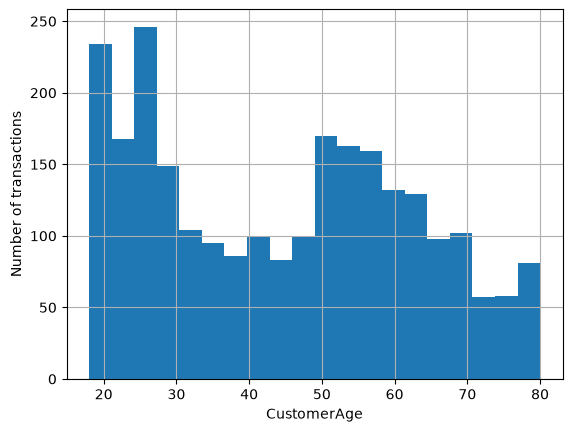

CustomerOccupation
Student     657
Doctor      631
Engineer    625
Retired     599
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
CustomerOccupation,,,,,,,,
Doctor,631.0,49.581616,12.449233,29.0,39.0,50.0,61.0,70.0
Engineer,625.0,42.648000,10.273859,26.0,34.0,42.0,51.0,60.0
Retired,599.0,65.315526,8.701033,51.0,57.0,65.0,73.0,80.0
Student,657.0,23.068493,3.134174,18.0,20.0,23.0,26.0,28.0


In [12]:
data_transaction["CustomerAge"].hist(bins=20)
plt.xlabel("CustomerAge")
plt.ylabel("Number of transactions")
plt.show()

print(data_transaction["CustomerOccupation"].value_counts())
display(data_transaction.groupby("CustomerOccupation")["CustomerAge"].describe())

### 6.6 Transaction Duration & Channel (no relationship)

One would expect different durations for ATM, branch and online transactions. The distributions are practically identical (means between 117 and 122, same spread), so the duration is independent of the channel.

,count,mean,std,min,25%,50%,75%,max
Channel,,,,,,,,
ATM,833.0,122.091236,69.815477,11.0,64.0,116.0,163.0,300.0
Branch,868.0,116.675115,70.051854,10.0,59.0,109.0,159.0,298.0
Online,811.0,120.305795,69.993264,10.0,65.0,114.0,161.5,300.0


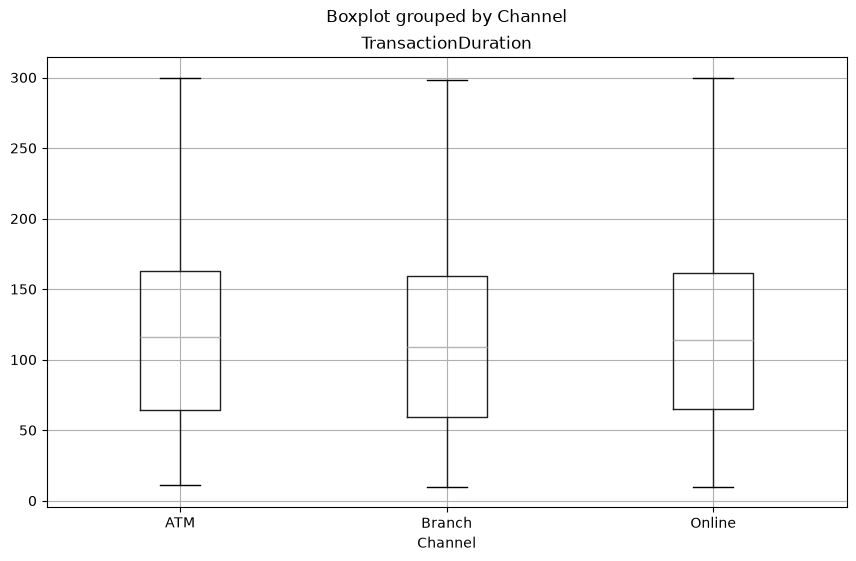

In [13]:
display(data_transaction.groupby("Channel")["TransactionDuration"].describe())

fig, ax = plt.subplots(figsize=(10, 6))
data_transaction.boxplot(column="TransactionDuration", by="Channel", ax=ax)
plt.show()

### 6.7 EDA Summary

| Idea | Verdict | Reason |
|---|---|---|
| Time since last transaction (`Transaction_diff`) | **use** | Per-account timestamps are consistent, verified by hand |
| `TransactionAmount`, `LoginAttempts`, `TransactionDuration`, `CustomerAge` | **use** | Plausible on their own, no history needed |
| Location deviation | discard | About 75% flagged, location looks random per transaction |
| IP / device / merchant consistency | discard | Almost one new value per transaction |
| Balance direction vs. transaction type | discard | About 50% mismatch, same as chance |
| Duration vs. channel | no link | Distributions are identical |

**Takeaway:** Features that need *consistent content history per account* do not work in this dataset. Features that are meaningful within a single row, plus the time between transactions, do. The idea of "deviation from the account's own behaviour" therefore has to be replaced by outliers relative to all transactions.

## 7. Prepare Features for the Model

`prepare_features` (in `src/feature_engineering.py`) does the following:
1. Computes `Transaction_diff` on the full data. This is a per-row calculation that learns nothing from the data.
2. Splits into train (70%) and test (30%).
3. Fills the missing `Transaction_diff` values of first transactions with the **median of the training set** and applies the same value to the test set (*fit on train, transform on test*, no leakage).
4. Keeps only the model features.

The median is used instead of `0`: a filled `0` would pile up about 20% of the rows at the extreme end of the feature and distort the anomaly scores.

`is_first_transaction` is created during preprocessing but is **not** a model feature. In an experiment with six features, removing it changed about 29% of the top-5% ranking, while a different random seed alone changed only about 11% (overlap 0.71 vs. 0.89, from an earlier version of this notebook). A flag that is set for every fifth row is easy for a tree to split on, but a first transaction is not suspicious by itself.

In [14]:
X_train, X_test = prepare_features(pd.read_csv("../data/bank_transactions_data_2.csv"))

print("Shapes (train, test):", X_train.shape, X_test.shape)
print("Missing values (train, test):", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print("Features:", FEATURES_FOR_MODEL)

Shapes (train, test): (1758, 5) (754, 5)
Missing values (train, test): 0 0
Features: ['TransactionAmount', 'LoginAttempts', 'TransactionDuration', 'CustomerAge', 'Transaction_diff']


## 8. Isolation Forest

Isolation Forest builds random trees: at each node it picks a random feature and a random split value between the minimum and maximum of that feature. Anomalies are isolated after few splits, so a **lower** `score_samples` value means a **more anomalous** transaction.

All comparisons below use the 5% most anomalous test transactions (`n_top`). Without labels this cut-off is only a convenient choice. The real share of fraud is unknown, and `contamination` would be an assumption, not a measured value.

In [15]:
# Size of the "top 5%" group used for all comparisons below
n_top = int(len(X_test) * 0.05)

iso = IsolationForest(random_state=RANDOM_STATE).fit(X_train)
scores_if = iso.score_samples(X_test)  # lower score = more anomalous

### 8.1 Does Scaling Matter?

Isolation Forest draws split values uniformly between the minimum and maximum of a feature, so a linear rescaling moves the thresholds but not the partitions. We check this instead of assuming it.

In [16]:
# Same model on MinMax-scaled data (scaler is fitted on the training data only)
scaler_mm = MinMaxScaler()
X_train_mm = scaler_mm.fit_transform(X_train)
X_test_mm = scaler_mm.transform(X_test)

iso_scaled = IsolationForest(random_state=RANDOM_STATE).fit(X_train_mm)
scores_if_scaled = iso_scaled.score_samples(X_test_mm)

print("Correlation of scores (unscaled vs. scaled):", np.corrcoef(scores_if, scores_if_scaled)[0, 1])

Correlation of scores (unscaled vs. scaled): 1.0


The correlation is 1.0, so scaling is not needed for Isolation Forest. It is needed for distance-based methods such as LOF (Section 9).

### 8.2 Most Anomalous Transactions

,TransactionAmount,LoginAttempts,TransactionDuration,CustomerAge,Transaction_diff,anomaly_score
1025,1294.81,1,279,45,5663.97,-0.697440
1724,1353.93,1,171,26,5257.14,-0.671742
581,1049.92,1,21,80,4272.78,-0.671420
511,1173.74,1,61,61,6312.70,-0.666816
679,88.06,1,288,18,5808.47,-0.656270
100,331.32,5,137,61,2520.80,-0.653353
1351,337.73,4,107,78,3048.32,-0.649618
2353,1431.30,1,168,18,3841.38,-0.646335
1310,611.11,4,282,20,336.86,-0.646132
2478,83.50,5,91,61,146.00,-0.645279


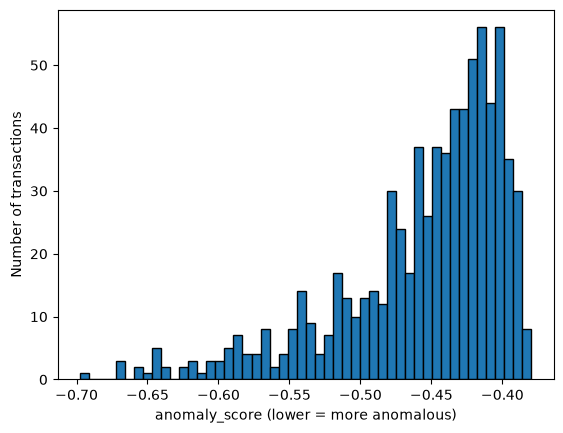

In [17]:
X_test_scored = X_test.copy()
X_test_scored["anomaly_score"] = scores_if

display(X_test_scored.nsmallest(10, "anomaly_score"))

plt.hist(X_test_scored["anomaly_score"], bins=50, edgecolor="black")
plt.xlabel("anomaly_score (lower = more anomalous)")
plt.ylabel("Number of transactions")
plt.show()

The ten most anomalous transactions mix three patterns: very high amounts (five above 1,000), many login attempts (four with 4 or 5) and unusually long durations (three with 279 to 288). Most scores form one dense group, and the anomalies sit in the thin tail on the left.

### 8.3 What Distinguishes the Flagged Transactions?

In [18]:
threshold = X_test_scored["anomaly_score"].quantile(0.05)
flagged = X_test_scored[X_test_scored["anomaly_score"] <= threshold]
rest = X_test_scored[X_test_scored["anomaly_score"] > threshold]

pd.DataFrame({
    "flagged": flagged[FEATURES_FOR_MODEL].mean(),
    "rest": rest[FEATURES_FOR_MODEL].mean(),
})

,flagged,rest
TransactionAmount,595.644474,284.319860
LoginAttempts,2.368421,1.048883
TransactionDuration,120.763158,119.856145
CustomerAge,44.605263,44.641061
Transaction_diff,3261.495526,1194.397486


The flagged group differs most in `LoginAttempts` (2.4 vs. 1.0), `TransactionAmount` (about 600 vs. 280) and `Transaction_diff` (about 3,260 vs. 1,190 hours). `CustomerAge` and `TransactionDuration` are practically identical. This fits the original hypotheses about login attempts and large amounts, and the model found them without any labels.

### 8.4 Stability Across Random Seeds

Isolation Forest is random. Before comparing models we measure how much its own top-5% group changes when only the seed changes. This is the noise level against which all model differences have to be judged.

In [19]:
def top_n_indices(X_tr: pd.DataFrame, X_te: pd.DataFrame, seed: int, n: int) -> set:
    """Return row positions of the n most anomalous test rows."""
    model = IsolationForest(random_state=seed).fit(X_tr)
    return set(np.argsort(model.score_samples(X_te))[:n])


# Overlap of the top-5% group between two different seeds, averaged over 10 pairs
seed_overlap = [
    len(top_n_indices(X_train, X_test, seed, n_top) & top_n_indices(X_train, X_test, seed + 100, n_top)) / n_top
    for seed in range(10)
]
print("Mean overlap between two seeds:", round(np.mean(seed_overlap), 3))

Mean overlap between two seeds: 0.854


Two seeds share about 85% of the top-5% group, so about 15% of it changes through randomness alone. Differences between models or feature sets that are smaller than this cannot be interpreted.

## 9. Local Outlier Factor (LOF)

LOF compares the local density around a transaction with the density around its `k` nearest neighbours. A transaction in a much sparser area than its neighbours is an outlier. It relies on distances, so the features **must be scaled**. We use the `RobustScaler` (median and interquartile range), which is not dominated by the outliers we are looking for. `novelty=True` allows scoring unseen data (fit on train, score on test). As before, a lower score means more anomalous.

In [20]:
scaler_rs = RobustScaler()
X_train_rs = scaler_rs.fit_transform(X_train)
X_test_rs = scaler_rs.transform(X_test)

lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X_train_rs)
scores_lof = lof.score_samples(X_test_rs)

### 9.1 Does Scaling Matter for LOF?

For comparison the same LOF on the raw features. LOF has no random seed, so any difference comes from the scaling.

In [21]:
# .to_numpy() avoids a harmless sklearn warning about feature names
lof_raw = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X_train.to_numpy())
scores_lof_raw = lof_raw.score_samples(X_test.to_numpy())

### 9.2 Comparison of the Models

First the overlap of the top-5% groups, then the profile of each group: how many standard deviations the mean of the flagged rows lies above the overall mean of each feature (z-profile). Dividing by the standard deviation makes the features comparable.

In [22]:
top_if = np.argsort(scores_if)[:n_top]
top_lof = np.argsort(scores_lof)[:n_top]
top_lof_raw = np.argsort(scores_lof_raw)[:n_top]


def overlap(a: np.ndarray, b: np.ndarray) -> str:
    """Number and share of row positions that appear in both groups."""
    common = len(np.intersect1d(a, b))
    return f"{common} of {len(a)} ({common / len(a):.2f})"


print("Isolation Forest vs. LOF (scaled):", overlap(top_if, top_lof))
print("LOF (scaled) vs. LOF (raw):       ", overlap(top_lof, top_lof_raw))


def z_profile(X_ref: pd.DataFrame, top_idx: np.ndarray) -> pd.Series:
    """Mean deviation of flagged rows, in units of the overall standard deviation."""
    return (X_ref.iloc[top_idx].mean() - X_ref.mean()) / X_ref.std()


profiles = pd.DataFrame({
    "IF": z_profile(X_test, top_if),
    "LOF scaled": z_profile(X_test, top_lof),
    "LOF raw": z_profile(X_test, top_lof_raw),
})
display(profiles.round(2))

Isolation Forest vs. LOF (scaled): 13 of 37 (0.35)
LOF (scaled) vs. LOF (raw):        10 of 37 (0.27)


,IF,LOF scaled,LOF raw
TransactionAmount,1.02,1.14,1.71
LoginAttempts,2.20,0.53,0.09
TransactionDuration,-0.00,0.37,0.17
CustomerAge,0.02,-0.03,0.07
Transaction_diff,1.71,0.79,0.60


**Observations**
- Isolation Forest and scaled LOF share 13 of 37 transactions. The two methods find different things, so they complement each other.
- Scaling changes LOF a lot: scaled and raw LOF share only 10 of 37 transactions. LOF has no random seed, so this difference comes entirely from the scaling.
- Isolation Forest reacts most to `LoginAttempts` (2.20) and `Transaction_diff` (1.71). Scaled LOF reacts most to `TransactionAmount` (1.14), and the raw LOF almost ignores `LoginAttempts` (0.09).
- Not yet explained: the raw LOF puts more weight on `TransactionAmount` (1.71) than on `Transaction_diff` (0.60), although `Transaction_diff` has the larger numbers. LOF compares densities rather than plain distances, so the simple "large numbers dominate" explanation is not enough.
- Without labels we cannot say which method is better, only how they differ.

### Open Question and Next Steps

- **Open:** Even the scaled LOF barely reacts to `LoginAttempts` (z = 0.53). Check `scaler_rs.scale_` and think about what the `RobustScaler` does to a feature whose quartiles are almost identical.
- Compare more methods (One-Class SVM, K-Means distance).
- Without labels there is no accuracy or F1. We need other ways to judge the models, for example stability, agreement between methods and a plausibility check of the flagged transactions.
- Treat `contamination` as a sensitivity parameter (for example 1%, 2%, 5%), not as a fixed value.

In [23]:
print(dict(zip(X_train.columns, scaler_rs.scale_)))

{'TransactionAmount': np.float64(325.135), 'LoginAttempts': np.float64(1.0), 'TransactionDuration': np.float64(98.0), 'CustomerAge': np.float64(32.0), 'Transaction_diff': np.float64(1006.575)}


In [25]:
rows = []
for k in [20, 50, 100]:
    lof_k = LocalOutlierFactor(n_neighbors=k, novelty=True).fit(X_train_rs)
    top_k = np.argsort(lof_k.score_samples(X_test_rs))[:n_top]
    rows.append({
        "k": k,
        "share LoginAttempts >= 2": (X_test.iloc[top_k]["LoginAttempts"] >= 2).mean(),
        "overlap with IF": len(np.intersect1d(top_k, top_if)),
        **z_profile(X_test, top_k).round(2).to_dict(),
    })

pd.DataFrame(rows).set_index("k").round(2)

,share LoginAttempts >= 2,overlap with IF,TransactionAmount,LoginAttempts,TransactionDuration,CustomerAge,Transaction_diff
k,,,,,,,
20,0.35,13,1.14,0.53,0.37,-0.03,0.79
50,0.62,15,0.91,1.51,-0.11,-0.22,0.60
100,0.73,23,0.69,3.38,-0.02,-0.12,0.61
